In [1]:
# ============================================================
# GM(1,7) Prediction Model
# Source:
# Grey Systems Theory and Applications
# Chapter 4
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [2]:
# ============================================================
# Load Dataset GM(1,7)
# ============================================================

import pandas as pd

df = pd.read_csv("data_gm.csv")

display(df.head())

,kecamatan,periode,Warna,Besi,Mangan,Nitrat,Nitrit,Total Coliform,E. Coli,IKKA
0,CAKUNG,2022 P1,0.297573,0.313560,0.068074,0.015293,0.049764,0.000168,0.000168,79.725751
1,CAKUNG,2022 P2,0.206759,0.191193,0.052734,0.016333,0.039901,0.000017,0.000017,83.911086
2,CAKUNG,2023 P1,0.145759,0.307647,0.089346,0.044634,0.041134,0.000095,0.000027,80.493276
3,CAKUNG,2023 P2,0.310138,0.441965,0.064239,0.056485,0.708523,0.000060,0.000000,95.402016
4,CAKUNG,2024 P1,0.060440,0.154853,0.063582,0.231228,0.012604,0.000054,0.000000,91.319836


In [53]:
print(df["IKKA"].min(), df["IKKA"].max())

60.28326504981696 100.0


In [3]:
# ============================================================
# Validasi Jumlah Periode per Kecamatan
# ============================================================

cek_periode = (
    df.groupby("kecamatan")["periode"]
      .count()
      .sort_values()
)

display(cek_periode)

kecamatan
CAKUNG               6
MAMPANG PRAPATAN     6
MATRAMAN             6
MENTENG              6
PADEMANGAN           6
PALMERAH             6
PANCORAN             6
PASAR MINGGU         6
PASAR REBO           6
PENJARINGAN          6
PESANGGRAHAN         6
PULO GADUNG          6
SAWAH BESAR          6
SENEN                6
SETIABUDI            6
TAMAN SARI           6
TAMBORA              6
TANAH ABANG          6
MAKASAR              6
KRAMAT JATI          6
KOJA                 6
KEMBANGAN            6
CEMPAKA PUTIH        6
CENGKARENG           6
CILANDAK             6
CILINCING            6
CIPAYUNG             6
CIRACAS              6
DUREN SAWIT          6
GAMBIR               6
TANJUNG PRIOK        6
GROGOL PETAMBURAN    6
JATINEGARA           6
JOHAR BARU           6
KALIDERES            6
KEBAYORAN BARU       6
KEBAYORAN LAMA       6
KEBON JERUK          6
KELAPA GADING        6
KEMAYORAN            6
JAGAKARSA            6
TEBET                6
Name: periode, dtype: in

In [4]:
# ============================================================
# STEP 1
# Accumulated Generating Operation (AGO)
#
# Source:
# Grey Systems Theory and Applications
#
# x_i^(1)(k) = Σ x_i^(0)(j)
# ============================================================

In [5]:
# ============================================================
# Contoh Satu Kecamatan
# ============================================================

contoh = "CAKUNG"

data = (
    df[df["kecamatan"] == contoh]
    .sort_values("periode")
    .reset_index(drop=True)
)

display(data)

,kecamatan,periode,Warna,Besi,Mangan,Nitrat,Nitrit,Total Coliform,E. Coli,IKKA
0,CAKUNG,2022 P1,0.297573,0.313560,0.068074,0.015293,0.049764,0.000168,0.000168,79.725751
1,CAKUNG,2022 P2,0.206759,0.191193,0.052734,0.016333,0.039901,0.000017,0.000017,83.911086
2,CAKUNG,2023 P1,0.145759,0.307647,0.089346,0.044634,0.041134,0.000095,0.000027,80.493276
3,CAKUNG,2023 P2,0.310138,0.441965,0.064239,0.056485,0.708523,0.000060,0.000000,95.402016
4,CAKUNG,2024 P1,0.060440,0.154853,0.063582,0.231228,0.012604,0.000054,0.000000,91.319836
5,CAKUNG,2024 P2,0.039491,0.385369,0.084158,0.047005,0.026165,0.000133,0.000000,94.313435


In [6]:
# ============================================================
# AGO
# ============================================================

Y0 = data["IKKA"].values

X20 = data["Warna"].values
X30 = data["Besi"].values
X40 = data["Mangan"].values
X50 = data["Nitrat"].values
X60 = data["Nitrit"].values
X70 = data["Total Coliform"].values
X80 = data["E. Coli"].values


Y1 = np.cumsum(Y0)

X21 = np.cumsum(X20)
X31 = np.cumsum(X30)
X41 = np.cumsum(X40)
X51 = np.cumsum(X50)
X61 = np.cumsum(X60)
X71 = np.cumsum(X70)
X81 = np.cumsum(X80)

In [7]:
# ============================================================
# Notation According to Liu & Lin
# ============================================================

# Original sequence
x1_0 = Y0

# AGO sequence
x1_1 = Y1

In [8]:
hasil_ago = pd.DataFrame({

    "Periode":data["periode"],

    "IKKA":Y0,
    "AGO_IKKA":Y1,

    "Warna":X20,
    "AGO_Warna":X21

})

display(hasil_ago)

,Periode,IKKA,AGO_IKKA,Warna,AGO_Warna
0,2022 P1,79.725751,79.725751,0.297573,0.297573
1,2022 P2,83.911086,163.636837,0.206759,0.504331
2,2023 P1,80.493276,244.130113,0.145759,0.650090
3,2023 P2,95.402016,339.532129,0.310138,0.960228
4,2024 P1,91.319836,430.851965,0.060440,1.020668
5,2024 P2,94.313435,525.165399,0.039491,1.060160


In [9]:
# ============================================================
# Background Value
# Equation (4.16)
# ============================================================

Z1 = 0.5 * (Y1[:-1] + Y1[1:])

In [10]:
hasil_bg = pd.DataFrame({

    "Periode": data["periode"].iloc[1:].values,

    "AGO_IKKA(k-1)": Y1[:-1],

    "AGO_IKKA(k)": Y1[1:],

    "Z1": Z1

})

display(hasil_bg)

,Periode,AGO_IKKA(k-1),AGO_IKKA(k),Z1
0,2022 P2,79.725751,163.636837,121.681294
1,2023 P1,163.636837,244.130113,203.883475
2,2023 P2,244.130113,339.532129,291.831121
3,2024 P1,339.532129,430.851965,385.192047
4,2024 P2,430.851965,525.165399,478.008682


In [11]:
# ============================================================
# Matrix B (Theorem 4.12)
# ============================================================

B = np.column_stack([

    -Z1,

    X21[1:],
    X31[1:],
    X41[1:],
    X51[1:],
    X61[1:],
    X71[1:],
    X81[1:]

])

print("Ukuran Matrix B :", B.shape)

display(pd.DataFrame(B))

Ukuran Matrix B : (5, 8)


,0,1,2,3,4,5,6,7
0,-121.681294,0.504331,0.504754,0.120808,0.031626,0.089665,0.000185,0.000185
1,-203.883475,0.650090,0.812400,0.210153,0.076261,0.130799,0.000280,0.000212
2,-291.831121,0.960228,1.254366,0.274392,0.132745,0.839322,0.000340,0.000212
3,-385.192047,1.020668,1.409219,0.337974,0.363973,0.851926,0.000394,0.000212
4,-478.008682,1.060160,1.794589,0.422132,0.410978,0.878091,0.000527,0.000212


In [12]:
# ============================================================
# Vector Y (Theorem 4.12)
# ============================================================

Y = Y0[1:].reshape(-1,1)

print("Ukuran Vector Y :", Y.shape)

display(pd.DataFrame(Y, columns=["IKKA"]))

Ukuran Vector Y : (5, 1)


,IKKA
0,83.911086
1,80.493276
2,95.402016
3,91.319836
4,94.313435


In [13]:
# ============================================================
# Validasi Dimensi Matrix
# ============================================================

print("B      :", B.shape)
print("B.T    :", B.T.shape)

BTB = B.T @ B

print("B.T @ B :", BTB.shape)

BTY = B.T @ Y

print("B.T @ Y :", BTY.shape)

B      : (5, 8)
B.T    : (8, 5)
B.T @ B : (8, 8)
B.T @ Y : (8, 1)


In [14]:
# ============================================================
# Validasi Matrix sebelum Least Squares
# matrix validation
# ============================================================

BTB = B.T @ B

print("Rank B     :", np.linalg.matrix_rank(B))
print("Rank B.TB  :", np.linalg.matrix_rank(BTB))

print("Shape B    :", B.shape)
print("Shape B.TB :", BTB.shape)

print("Det(B.TB)  :", np.linalg.det(BTB))

Rank B     : 5
Rank B.TB  : 5
Shape B    : (5, 8)
Shape B.TB : (8, 8)
Det(B.TB)  : -3.781945727564978e-61


In [15]:
# ============================================================
# Least Squares Estimation menggunakan
# Truncated Singular Value Decomposition (TSVD)
#
# Theoretical:
# θ = Vk Σk⁻¹ Ukᵀ Y
#
# TSVD digunakan sebagai pengganti Moore-Penrose
# Pseudo Inverse untuk memperoleh estimasi parameter
# yang lebih stabil pada matriks yang singular atau
# ill-conditioned.
# ============================================================

# Singular Value Decomposition
U, S, Vt = np.linalg.svd(B, full_matrices=False)

# Truncation parameter
# Menghilangkan singular value terkecil
k = 3

# Matriks hasil truncation
Uk = U[:, :k]
Sk = S[:k]
Vk = Vt[:k, :].T

# Estimasi parameter TSVD
theta = Vk @ np.diag(1.0 / Sk) @ Uk.T @ Y

print("Theta Shape :", theta.shape)
print("Singular Values :", S)
print(f"Truncation k = {k}")

display(pd.DataFrame(
    theta,
    index=[
        "a",
        "b2",
        "b3",
        "b4",
        "b5",
        "b6",
        "b7",
        "b8"
    ],
    columns=["Value"]
))

Theta Shape : (8, 1)
Singular Values : [7.20013548e+02 4.27593634e-01 3.97606866e-01 1.13914274e-01
 1.16857357e-02]
Truncation k = 3


,Value
a,0.152928
b2,138.427086
b3,49.995257
b4,13.054187
b5,-61.879698
b6,-55.886436
b7,0.031012
b8,0.070286


In [16]:
# ============================================================
# Validation of Estimated Parameters
# ============================================================

print("NaN :", np.isnan(theta).sum())
print("Inf :", np.isinf(theta).sum())

NaN : 0
Inf : 0


In [17]:
# ============================================================
# Extract Parameters
# ============================================================

a = theta[0, 0]

b2 = theta[1, 0]
b3 = theta[2, 0]
b4 = theta[3, 0]
b5 = theta[4, 0]
b6 = theta[5, 0]
b7 = theta[6, 0]
b8 = theta[7, 0]

print(f"a  = {a:.8f}")
print(f"b2 = {b2:.8f}")
print(f"b3 = {b3:.8f}")
print(f"b4 = {b4:.8f}")
print(f"b5 = {b5:.8f}")
print(f"b6 = {b6:.8f}")
print(f"b7 = {b7:.8f}")
print(f"b8 = {b8:.8f}")

a  = 0.15292830
b2 = 138.42708578
b3 = 49.99525698
b4 = 13.05418697
b5 = -61.87969794
b6 = -55.88643626
b7 = 0.03101228
b8 = 0.07028630


In [18]:
# ============================================================
# Estimated GM(1,7) Parameters
# ============================================================

parameter = pd.DataFrame({
    "Parameter": [
        "a",
        "b₂",
        "b₃",
        "b₄",
        "b₅",
        "b₆",
        "b₇",
        "b₈"
    ],
    "Estimated Value": [
        a,
        b2,
        b3,
        b4,
        b5,
        b6,
        b7,
        b8
    ]
})

display(parameter.round(6))

,Parameter,Estimated Value
0,a,0.152928
1,b₂,138.427086
2,b₃,49.995257
3,b₄,13.054187
4,b₅,-61.879698
5,b₆,-55.886436
6,b₇,0.031012
7,b₈,0.070286


In [19]:
# ============================================================
# Estimated GM(1,7) Model
# ============================================================

from IPython.display import Latex, display

equation = rf"""
$$
\frac{{dx_1^{{(1)}}}}{{dt}}
+
{a:.6f}x_1^{{(1)}}
=
{b2:.6f}x_2^{{(1)}}
+
{b3:.6f}x_3^{{(1)}}
{b4:+.6f}x_4^{{(1)}}
{b5:+.6f}x_5^{{(1)}}
{b6:+.6f}x_6^{{(1)}}
{b7:+.6f}x_7^{{(1)}}
{b8:+.6f}x_8^{{(1)}}
$$
"""

display(Latex(equation))

<IPython.core.display.Latex object>

In [20]:
# ============================================================
# Driving Term
# Equation (4.19)
# Σ b_i x_i^(1)
# ============================================================

S = (
    b2 * X21 +
    b3 * X31 +
    b4 * X41 +
    b5 * X51 +
    b6 * X61 +
    b7 * X71 +
    b8 * X81
)

print("Shape S :", S.shape)

display(pd.DataFrame({
    "k": np.arange(1, len(S)+1),
    "Σ bᵢxᵢ^(1)": S
}))

Shape S : (6,)


,k,Σ bᵢxᵢ^(1)
0,1,54.029863
1,2,89.657376
2,3,121.320819
3,4,144.094991
4,5,146.020747
5,6,167.481772


In [21]:
# ============================================================
# Validation Driving Term
# ============================================================

print("NaN :", np.isnan(S).sum())
print("Inf :", np.isinf(S).sum())
print("Min :", S.min())
print("Max :", S.max())

NaN : 0
Inf : 0
Min : 54.0298625339199
Max : 167.48177162252412


In [22]:
# ============================================================
# Approximate Time Response Sequence
# Equation (4.19)
# ============================================================

k = np.arange(len(S))

x1_1_hat = (
    (x1_0[0] - (S / a))
    * np.exp(-a * k)
    + (S / a)
)

print("Shape :", x1_1_hat.shape)

display(pd.DataFrame({
    "k": np.arange(1, len(x1_1_hat)+1),
    "x̂₁⁽¹⁾": x1_1_hat
}))

Shape : (6,)


,k,x̂₁⁽¹⁾
0,1,79.725751
1,2,151.558251
2,3,267.762937
3,4,397.086438
4,5,480.155909
5,6,622.477410


In [23]:
# ============================================================
# Validation Time Response
# ============================================================

print("NaN :", np.isnan(x1_1_hat).sum())
print("Inf :", np.isinf(x1_1_hat).sum())
print("Min :", x1_1_hat.min())
print("Max :", x1_1_hat.max())

NaN : 0
Inf : 0
Min : 79.72575136842738
Max : 622.4774103949125


In [24]:
display(pd.DataFrame({
    "k": np.arange(1, len(x1_1_hat)+1),
    "x̂₁^(1)": x1_1_hat
}))

,k,x̂₁^(1)
0,1,79.725751
1,2,151.558251
2,3,267.762937
3,4,397.086438
4,5,480.155909
5,6,622.477410


In [25]:
# ============================================================
# Restored Sequence of Inverse Accumulation (IAGO)
# Theorem 4.13 (3)
# ============================================================

# Allocate memory
x1_0_hat = np.empty_like(x1_1_hat)

# Initial condition
# Theorem 4.13 does not explicitly define x̂₁⁽⁰⁾(1).
# Therefore, the first value is initialized using
# the original sequence x₁⁽⁰⁾(1).

x1_0_hat[0] = x1_0[0]

# Equation (Theorem 4.13 point 3)
# x̂₁⁽⁰⁾(k+1) = x̂₁⁽¹⁾(k+1) − x̂₁⁽¹⁾(k)

x1_0_hat[1:] = (
    x1_1_hat[1:]
    - x1_1_hat[:-1]
)

print("Shape :", x1_0_hat.shape)

display(pd.DataFrame({
    "k": np.arange(1, len(x1_0_hat)+1),
    "x̂₁^(0)": x1_0_hat
}))

Shape : (6,)


,k,x̂₁^(0)
0,1,79.725751
1,2,71.832500
2,3,116.204685
3,4,129.323501
4,5,83.069471
5,6,142.321501


In [26]:
# ============================================================
# Validation IAGO
# ============================================================

print("NaN :", np.isnan(x1_0_hat).sum())
print("Inf :", np.isinf(x1_0_hat).sum())
print("Min :", x1_0_hat.min())
print("Max :", x1_0_hat.max())

NaN : 0
Inf : 0
Min : 71.83249983120618
Max : 142.3215012416489


In [27]:
print(x1_0[0])

79.7257513684274


In [28]:
# ============================================================
# Actual vs Predicted Values
# ============================================================

prediction_result = pd.DataFrame({
    "Period": [f"t{i}" for i in range(1, len(x1_0)+1)],
    "Actual": x1_0,
    "Predicted": x1_0_hat
})

display(prediction_result.round(6))

,Period,Actual,Predicted
0,t1,79.725751,79.725751
1,t2,83.911086,71.832500
2,t3,80.493276,116.204685
3,t4,95.402016,129.323501
4,t5,91.319836,83.069471
5,t6,94.313435,142.321501


In [29]:
# ============================================================
# Residual Error
# ============================================================

error = x1_0 - x1_0_hat

error_result = pd.DataFrame({
    "Period": [f"t{i}" for i in range(1, len(x1_0)+1)],
    "Actual": x1_0,
    "Predicted": x1_0_hat,
    "Residual": error
})

display(error_result.round(6))

,Period,Actual,Predicted,Residual
0,t1,79.725751,79.725751,0.000000
1,t2,83.911086,71.832500,12.078586
2,t3,80.493276,116.204685,-35.711409
3,t4,95.402016,129.323501,-33.921486
4,t5,91.319836,83.069471,8.250365
5,t6,94.313435,142.321501,-48.008067


In [30]:
mae = np.mean(np.abs(error))

print(f"MAE : {mae:.6f}")

MAE : 22.994985


In [31]:
rmse = np.sqrt(np.mean(error**2))

print(f"RMSE : {rmse:.6f}")

RMSE : 28.707453


In [32]:
mape = np.mean(np.abs(error / x1_0)) * 100

print(f"MAPE : {mape:.2f}%")

MAPE : 25.71%


In [33]:
S1 = np.std(x1_0, ddof=1)
S2 = np.std(error, ddof=1)

C = S2 / S1

print(f"Posterior Error Ratio (C) : {C:.6f}")

Posterior Error Ratio (C) : 3.700301


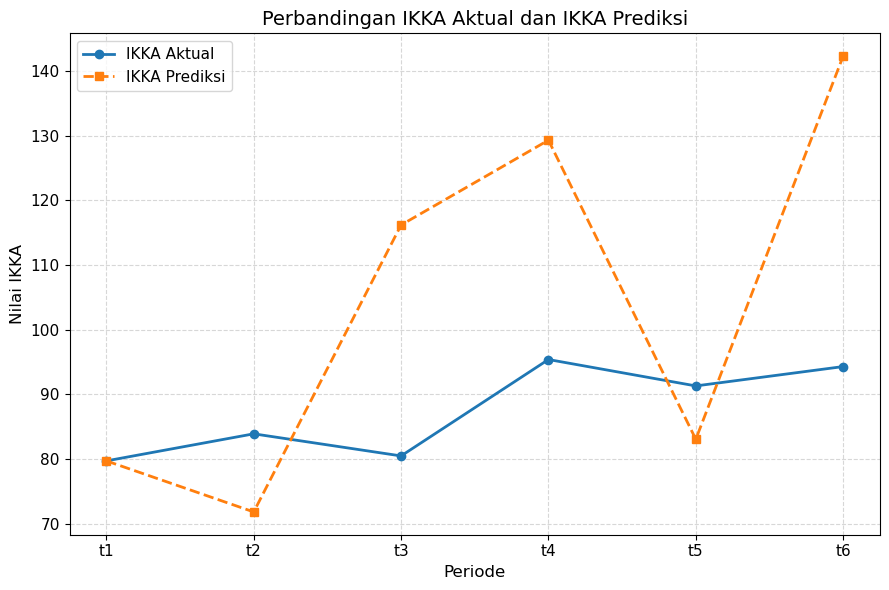

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,6))

plt.plot(
    prediction_result["Period"],
    prediction_result["Actual"],
    marker="o",
    linewidth=2,
    label="IKKA Aktual"
)

plt.plot(
    prediction_result["Period"],
    prediction_result["Predicted"],
    marker="s",
    linewidth=2,
    linestyle="--",
    label="IKKA Prediksi"
)

plt.title("Perbandingan IKKA Aktual dan IKKA Prediksi", fontsize=14)
plt.xlabel("Periode", fontsize=12)
plt.ylabel("Nilai IKKA", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.grid(True, linestyle="--", alpha=0.5)

plt.legend(fontsize=11)

plt.tight_layout()

# Simpan gambar dengan resolusi tinggi
plt.savefig(
    "grafik_ikka_aktual_vs_prediksi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
plt.savefig(
    "grafik_ikka_aktual_vs_prediksi.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [36]:
def gm17_model(df_kecamatan):
    """
    GM(1,7) Model
    Input  : Data satu kecamatan (6 periode)
    Output : Prediksi IKKA dan metrik evaluasi
    """
    # ============================================================
    # Ekstraksi variabel model GM(1,7)
    # ============================================================

    # Variabel dependen (x1^(0))
    Y0 = df_kecamatan["IKKA"].values.astype(float)

    # Variabel independen (x2^(0) - x8^(0))
    X2 = df_kecamatan["Warna"].values.astype(float)
    X3 = df_kecamatan["Besi"].values.astype(float)
    X4 = df_kecamatan["Mangan"].values.astype(float)
    X5 = df_kecamatan["Nitrat"].values.astype(float)
    X6 = df_kecamatan["Nitrit"].values.astype(float)
    X7 = df_kecamatan["Total Coliform"].values.astype(float)
    X8 = df_kecamatan["E. Coli"].values.astype(float)
   

    # ============================================================
    # Accumulated Generating Operation (AGO)
    # ============================================================
    Y1 = np.cumsum(Y0)
    X21 = np.cumsum(X2)
    X31 = np.cumsum(X3)
    X41 = np.cumsum(X4)
    X51 = np.cumsum(X5)
    X61 = np.cumsum(X6)
    X71 = np.cumsum(X7)
    X81 = np.cumsum(X8)

    # ============================================================
    # Alias
    # ============================================================

    x1_0 = Y0
    x1_1 = Y1

    # ============================================================
    # Background Value
    # # Equation (4.16)
    # # ============================================================
    
    Z1 = 0.5 * (Y1[:-1] + Y1[1:])

    # ============================================================
    # Matrix B (Theorem 4.12)
    # ============================================================
    B = np.column_stack([
       -Z1,
       X21[1:],
       X31[1:],
       X41[1:],
       X51[1:],
       X61[1:],
       X71[1:],
       X81[1:]

])

    # ============================================================
    # Vector Y (Theorem 4.12)
    # ============================================================
    Y = Y0[1:].reshape(-1,1)

    # ============================================================
    # Least Squares Estimation menggunakan
    # Truncated Singular Value Decomposition (TSVD)
    # ============================================================

    # Singular Value Decomposition
    U, sigma, Vt = np.linalg.svd(B, full_matrices=False)

    # Truncation Parameter
    # Menghilangkan singular value terkecil
    k_tsvd = 3

    # Matriks hasil truncation
    Uk = U[:, :k_tsvd]
    Sigmak = np.diag(sigma[:k_tsvd])
    Vk = Vt[:k_tsvd, :].T

    # Estimasi parameter TSVD
    theta = Vk @ np.linalg.inv(Sigmak) @ Uk.T @ Y


    # ============================================================
    # Parameter Estimation
    # ============================================================

    a = theta[0, 0]

    b2 = theta[1, 0]
    b3 = theta[2, 0]
    b4 = theta[3, 0]
    b5 = theta[4, 0]
    b6 = theta[5, 0]
    b7 = theta[6, 0]
    b8 = theta[7, 0]

    # ============================================================
    # Driving Term
    # ============================================================

    S = (
        b2 * X21 +
        b3 * X31 +
        b4 * X41 +
        b5 * X51 +
        b6 * X61 +
        b7 * X71 +
        b8 * X81
    )

    # ============================================================
    # Approximate Time Response Function
    # ============================================================

    k = np.arange(len(S))

    x1_1_hat = (
        (x1_0[0] - (S / a))
        * np.exp(-a * k)
        + (S / a)
    )
    
    # ============================================================
    # Inverse AGO (IAGO)
    # ============================================================

    x1_0_hat = np.empty_like(x1_1_hat)

    x1_0_hat[0] = x1_0[0]

    x1_0_hat[1:] = (
        x1_1_hat[1:]
        - x1_1_hat[:-1]
    )

    # ============================================================
    # Residual Error
    # ============================================================

    error = x1_0 - x1_0_hat

    error_result = pd.DataFrame({
        "Period": [f"t{i}" for i in range(1, len(x1_0)+1)],
        "Actual": x1_0,
        "Predicted": x1_0_hat,
        "Residual": error
    })

    # ============================================================
    # MAE
    # ============================================================

    mae = np.mean(np.abs(error))


    # ============================================================
    # RMSE
    # ============================================================

    rmse = np.sqrt(np.mean(error**2))


    # ============================================================
    # MAPE
    # ============================================================

    mape = np.mean(np.abs(error / x1_0)) * 100


    # ============================================================
    # Negative Prediction Check
    # ============================================================

    negative = np.any(x1_0_hat < 0)


    # ============================================================
    # Return
    # ============================================================

    return {
        "Actual": x1_0,
        "Predicted": x1_0_hat,
        "Residual": error,
        "Error_Table": error_result,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "Negative": negative,
        "a": a,
        "S": S,
        "x1_1_hat": x1_1_hat,
}

In [37]:
hasil_matraman = gm17_model(
    df[df["kecamatan"]=="MATRAMAN"]
)

print("a =", hasil_matraman["a"])
print("S =", hasil_matraman["S"])
print("x1_1_hat =", hasil_matraman["x1_1_hat"])

a = 0.15495554802695485
S = [ 69.99612176  95.467465   103.11740612 130.36991485 145.31330316
 144.13017013]
x1_1_hat = [ 79.34983104 156.39797419 235.54224248 362.64246635 475.90743383
 538.08998731]


In [38]:
hasil = gm17_model(data)

In [39]:
print(data["kecamatan"].unique())

['CAKUNG']


In [40]:
display(data[["kecamatan","periode","IKKA"]])

,kecamatan,periode,IKKA
0,CAKUNG,2022 P1,79.725751
1,CAKUNG,2022 P2,83.911086
2,CAKUNG,2023 P1,80.493276
3,CAKUNG,2023 P2,95.402016
4,CAKUNG,2024 P1,91.319836
5,CAKUNG,2024 P2,94.313435


In [41]:
display(hasil["Error_Table"])

print(f"MAE      : {hasil['MAE']:.6f}")
print(f"RMSE     : {hasil['RMSE']:.6f}")
print(f"MAPE     : {hasil['MAPE']:.2f}%")
print(f"Negative : {hasil['Negative']}")

,Period,Actual,Predicted,Residual
0,t1,79.725751,79.725751,0.000000
1,t2,83.911086,71.832500,12.078586
2,t3,80.493276,116.204685,-35.711409
3,t4,95.402016,129.323501,-33.921486
4,t5,91.319836,83.069471,8.250365
5,t6,94.313435,142.321501,-48.008067


MAE      : 22.994985
RMSE     : 28.707453
MAPE     : 25.71%
Negative : False


In [42]:
# ============================================================
# GM(1,7) untuk seluruh kecamatan
# ============================================================

hasil_semua = []

for kecamatan in sorted(df["kecamatan"].unique()):

    df_kecamatan = (
        df[df["kecamatan"] == kecamatan]
        .sort_values("periode")
        .reset_index(drop=True)
    )

    hasil = gm17_model(df_kecamatan)

    hasil_semua.append({
        "Kecamatan": kecamatan,
        "MAE": hasil["MAE"],
        "RMSE": hasil["RMSE"],
        "MAPE": hasil["MAPE"],
        "Negative": hasil["Negative"]
    })

In [43]:
hasil_gm17 = pd.DataFrame(hasil_semua)

display(hasil_gm17)

,Kecamatan,MAE,RMSE,MAPE,Negative
0,CAKUNG,22.994985,28.707453,25.708972,False
1,CEMPAKA PUTIH,46.564460,86.459801,50.732600,True
2,CENGKARENG,21.522095,37.652869,23.526899,False
3,CILANDAK,15.568429,23.435343,19.707711,False
4,CILINCING,23.456145,35.884154,31.673992,False
5,CIPAYUNG,13.251834,21.062096,15.986587,False
6,CIRACAS,35.849129,48.954915,45.022834,False
7,DUREN SAWIT,15.242110,21.763741,17.362469,False
8,GAMBIR,64.863070,81.592357,83.343619,True
9,GROGOL PETAMBURAN,19.112202,30.530994,21.673207,False


In [44]:
print("Jumlah Kecamatan :", len(hasil_gm17))
print(f"Rata-rata MAE  : {hasil_gm17['MAE'].mean():.6f}")
print(f"Rata-rata RMSE : {hasil_gm17['RMSE'].mean():.6f}")
print(f"Rata-rata MAPE : {hasil_gm17['MAPE'].mean():.2f}%")

Jumlah Kecamatan : 42
Rata-rata MAE  : 506.523099
Rata-rata RMSE : 945.464717
Rata-rata MAPE : 646.88%


In [45]:
negatif = hasil_gm17[hasil_gm17["Negative"]]

print(f"Jumlah kecamatan dengan prediksi negatif: {len(negatif)}")

display(negatif)

Jumlah kecamatan dengan prediksi negatif: 14


,Kecamatan,MAE,RMSE,MAPE,Negative
1,CEMPAKA PUTIH,46.564460,86.459801,50.732600,True
8,GAMBIR,64.863070,81.592357,83.343619,True
10,JAGAKARSA,2133.879754,3554.433935,2550.993045,True
14,KEBAYORAN BARU,37.264575,63.625295,40.948270,True
19,KEMBANGAN,44.346627,63.059317,54.991550,True
25,MENTENG,289.060719,511.434322,361.640529,True
26,PADEMANGAN,73.857773,133.799393,105.517336,True
27,PALMERAH,222.792374,304.366600,287.451243,True
28,PANCORAN,2459.200920,4130.180062,2859.319978,True
29,PASAR MINGGU,1025.004021,1646.182063,1221.757482,True


In [46]:
df[df["kecamatan"] == "MATRAMAN"]

,kecamatan,periode,Warna,Besi,Mangan,Nitrat,Nitrit,Total Coliform,E. Coli,IKKA
144,MATRAMAN,2022 P1,0.126702,0.011054,0.071818,0.037920,0.051407,0.000232,0.000232,79.349831
145,MATRAMAN,2022 P2,0.043979,0.018636,0.046205,0.024654,0.051407,0.000338,0.000338,78.949912
146,MATRAMAN,2023 P1,0.006283,0.035694,0.048967,0.112955,0.096610,0.000232,0.000090,79.349831
147,MATRAMAN,2023 P2,0.051309,0.048204,0.067800,0.108390,0.059626,0.000139,0.000013,79.970070
148,MATRAMAN,2024 P1,0.006890,0.015664,0.048866,0.475266,0.034395,0.000045,0.000000,86.556256
149,MATRAMAN,2024 P2,0.005236,0.065642,0.053236,0.111344,0.034970,0.000422,0.000255,78.733612


In [47]:
df[df["kecamatan"] == "MATRAMAN"][["periode", "IKKA"]]

,periode,IKKA
144,2022 P1,79.349831
145,2022 P2,78.949912
146,2023 P1,79.349831
147,2023 P2,79.970070
148,2024 P1,86.556256
149,2024 P2,78.733612


In [48]:
df.groupby("kecamatan").size()

kecamatan
CAKUNG               6
CEMPAKA PUTIH        6
CENGKARENG           6
CILANDAK             6
CILINCING            6
CIPAYUNG             6
CIRACAS              6
DUREN SAWIT          6
GAMBIR               6
GROGOL PETAMBURAN    6
JAGAKARSA            6
JATINEGARA           6
JOHAR BARU           6
KALIDERES            6
KEBAYORAN BARU       6
KEBAYORAN LAMA       6
KEBON JERUK          6
KELAPA GADING        6
KEMAYORAN            6
KEMBANGAN            6
KOJA                 6
KRAMAT JATI          6
MAKASAR              6
MAMPANG PRAPATAN     6
MATRAMAN             6
MENTENG              6
PADEMANGAN           6
PALMERAH             6
PANCORAN             6
PASAR MINGGU         6
PASAR REBO           6
PENJARINGAN          6
PESANGGRAHAN         6
PULO GADUNG          6
SAWAH BESAR          6
SENEN                6
SETIABUDI            6
TAMAN SARI           6
TAMBORA              6
TANAH ABANG          6
TANJUNG PRIOK        6
TEBET                6
dtype: int64

In [49]:
print(B)

[[-1.21681294e+02  5.04331271e-01  5.04753673e-01  1.20807733e-01
   3.16262854e-02  8.96650914e-02  1.85411941e-04  1.85411941e-04]
 [-2.03883475e+02  6.50090433e-01  8.12400491e-01  2.10153407e-01
   7.62605104e-02  1.30799260e-01  2.80147969e-04  2.12479377e-04]
 [-2.91831121e+02  9.60228463e-01  1.25436598e+00  2.74392439e-01
   1.32745437e-01  8.39322338e-01  3.39907244e-04  2.12479377e-04]
 [-3.85192047e+02  1.02066825e+00  1.40921940e+00  3.37974015e-01
   3.63973281e-01  8.51926171e-01  3.93986878e-04  2.12479377e-04]
 [-4.78008682e+02  1.06015965e+00  1.79458862e+00  4.22132431e-01
   4.10978483e-01  8.78090720e-01  5.26562077e-04  2.12479377e-04]]


In [50]:
print(B.shape)

(5, 8)


In [51]:
print(theta)

[[ 1.52928299e-01]
 [ 1.38427086e+02]
 [ 4.99952570e+01]
 [ 1.30541870e+01]
 [-6.18796979e+01]
 [-5.58864363e+01]
 [ 3.10122771e-02]
 [ 7.02863001e-02]]


In [52]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Warna,252.0,0.095446,0.121665,0.000000,0.023780,0.055254,0.122120,1.0
Besi,252.0,0.106518,0.142369,0.000000,0.019491,0.055934,0.125633,1.0
Mangan,252.0,0.108420,0.134952,0.000000,0.033787,0.068627,0.141564,1.0
Nitrat,252.0,0.096552,0.128424,0.000000,0.024951,0.056575,0.111488,1.0
Nitrit,252.0,0.087295,0.147138,0.000000,0.022642,0.030039,0.076181,1.0
Total Coliform,252.0,0.012111,0.077107,0.000000,0.000046,0.000102,0.000298,1.0
E. Coli,252.0,0.008054,0.067196,0.000000,0.000000,0.000014,0.000171,1.0
IKKA,252.0,82.733869,8.515989,60.283265,77.627295,80.557238,89.583934,100.0
